In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd

import pyPamtra

In [2]:
xr.set_options(display_style='html')  
plt.rcParams.update({'font.size': 16})

# Radar reflectivity simulations for shallow liquid cloud

## Assumptions for droplets 
currently, monodisperse DSD with 20 micron diameter droplets

In [3]:
descriptorFile = np.array([
      #['hydro_name' 'as_ratio' 'liq_ice' 'rho_ms' 'a_ms' 'b_ms' 'alpha_as' 'beta_as' 'moment_in' 'nbin' 'dist_name' 'p_1' 'p_2' 'p_3' 'p_4' 'd_1' 'd_2' 'scat_name' 'vel_size_mod' 'canting']
       ('cwc_q', 1.0,  1, -99.0,   -99.0, -99.0,  -99.0, -99.0, 3, 1, 'mono', -99.0, -99.0,   -99.0,   -99.0,   2e-5,   -99., 'mie-sphere', 'khvorostyanov01_drops', -99.0)],
      dtype=[('hydro_name', 'S15'), ('as_ratio', '<f8'), ('liq_ice', '<i8'), ('rho_ms', '<f8'), ('a_ms', '<f8'), ('b_ms', '<f8'), ('alpha_as', '<f8'), ('beta_as', '<f8'), ('moment_in', '<i8'), ('nbin', '<i8'), ('dist_name', 'S15'), ('p_1', '<f8'), ('p_2', '<f8'), ('p_3', '<f8'), ('p_4', '<f8'), ('d_1', '<f8'), ('d_2', '<f8'), ('scat_name', 'S20'), ('vel_size_mod', 'S30'), ('canting', '<f8')]
      )
DF = pd.DataFrame(descriptorFile)
DF

,hydro_name,as_ratio,liq_ice,rho_ms,a_ms,b_ms,alpha_as,beta_as,moment_in,nbin,dist_name,p_1,p_2,p_3,p_4,d_1,d_2,scat_name,vel_size_mod,canting
0,b'cwc_q',1.0,1,-99.0,-99.0,-99.0,-99.0,-99.0,3,1,b'mono',-99.0,-99.0,-99.0,-99.0,0.00002,-99.0,b'mie-sphere',b'khvorostyanov01_drops',-99.0


## CLARA range resolution

In [4]:
radar_range_center = np.array([111.795395, 134.15448 , 156.51355 , 178.87263 , 201.23172 , 223.59079 ,
       245.94987 , 268.30896 , 290.66803 , 313.0271  , 335.3862  , 357.74527 ,
       380.10434 , 402.46344 , 424.8225  , 447.18158 , 469.54068 , 491.89975 ,
       514.25885 , 536.6179  , 558.977   , 581.33606,
       620.987  ,  647.98645,  674.9859 ,  701.98535,  728.98474,  755.9842 ,
       782.98364,  809.98303,  836.9825 ,  863.98193,  890.9814 ,  917.98083,
       944.9802 ,  971.9797 ,  998.9791 , 1025.9785 , 1052.978  , 1079.9774 ,
       1106.9768 , 1133.9763 , 1160.9757 , 1187.9751 , 1214.9746 , 1241.974  ,
       1268.9735 , 1295.9729 , 1322.9723 , 1349.9718 , 1376.9712 , 1403.9707 ,
       1430.9701 , 1457.9695 , 1484.969  , 1511.9684 , 1538.9678 , 1565.9673 ,
       1592.9667 , 1619.9661 , 1646.9656 , 1673.965  , 1700.9645 , 1727.9639 ,
       1754.9633 , 1781.9628 , 1808.9622 , 1835.9617 , 1862.961  , 1889.9604 ,
       1916.96   , 1943.9594 , 1970.9587 , 1997.9583]  )               

In [5]:
radar_range_bounds = radar_range_center[:-1] - np.diff(radar_range_center)/2

In [6]:
radar_range_bounds = np.append(radar_range_bounds, radar_range_center[-2:] + np.diff(radar_range_center)[-2:]/2)

## Linear CWC distribution from 500 m upwards

assuming cloud in about 500 m above ground spanning x radar gates

In [7]:
radar_range_bounds[18]

503.0793250000001

In [8]:
cloud_gates = np.arange(1,radar_range_center.size-19,1)
cloud_gates

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54])

In [9]:
cwc = np.zeros((radar_range_center.size, cloud_gates.size))
cwc.shape

(74, 54)

In [10]:
for j in range(cloud_gates.size):
    cwc[18:19+cloud_gates[j],j] = np.linspace(0,1/1000,cloud_gates[j]+1) # -> density is about 1 so that kg/kg = kg/m3!

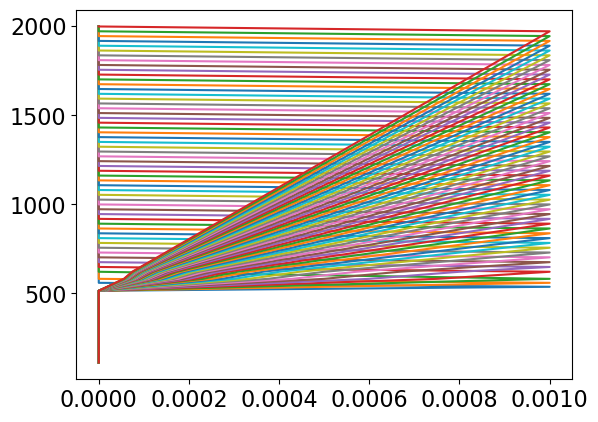

In [11]:
for j in range(cloud_gates.size):
    plt.plot(cwc[:,j], radar_range_center)

## Run simulations

In [12]:
# initiate pamtra
pam = pyPamtra.pyPamtra()
pam.set["verbose"] = 0
pam.set["pyVerbose"] = 0

# descriptor file --> monodisperse distribution
for df in descriptorFile:
      pam.df.addHydrometeor(df)
    
# create us standard atmosphere profile
pam = pyPamtra.importer.createUsStandardProfile(pam, hgt_lev=[list(radar_range_bounds)]*54)

pam.p['hgt'][:,0,:] = list(radar_range_center)

# add cloud water content in kg/kg 
pam.p['hydro_q'][:,0,:,0] = cwc[:,:].T # / np.diff(radar_range_bounds)

# active mode
pam.nmlSet["passive"] = False # passive mode
pam.nmlSet['active'] = True # active mode

pam.nmlSet["randomseed"] = 0 # 0 is real noise, -1 means that the seed is created from latitude and longitude, other value gives always the same random numbers

pam.nmlSet["radar_mode"] = "simple" # Use “simple” radar simulator provides only Z_e by integrating over D. The advanced “spectrum” simulator simulates the complete radar Doppler spectrum and estimates all moments from the spectrum. “moments” is identical to “spectrum” but the full Doppler spectrum is discarded to save memory.

pam.nmlSet["hydro_adaptive_grid"] = False 
pam.nmlSet["conserve_mass_rescale_dsd"] = False # In case the mass mixing ratio for an hydrometeor calculated integrating the drop-size-distribution (DSD) doesn’t correspond to the input value, rescale the DSD to account for the mass loss.

pam.nmlSet["radar_use_hildebrand"] = True # Derive N_P not from radar_pnoise0 but using the method of citet{hildebrand:1974a}. Set radar_noise_distance_factor<0 to use also noise_max from hildebrand for determination od the peak edge.
pam.nmlSet["radar_noise_distance_factor"] = -2 

# CLARA settings 
pam.nmlSet['radar_fwhr_beamwidth_deg']=[0.85,0.56]
pam.nmlSet['radar_integration_time']=1.0
# observation height of radar
pam.p['obs_height'][:,0] = 0
pam.nmlSet['radar_attenuation'] = 'bottom-up' # include attenuation by gas and hydrometeors


# run pamtra
frequencies = [35, 94]
pam.runPamtra(frequencies)
print((pam.fortError))

# output: pamtra height, Ze, hydro and atmo attentuation
Ze = pam.r['Ze'].squeeze()
att_hydro = pam.r['Att_hydro'].squeeze()
att_atmo = pam.r['Att_atmo'].squeeze()
Ze[Ze == -9.99900000e+03] = np.nan

/home/nmaherndl/lib/python/pyPamtra/core.py:821: Warning: timestamp set to now
  warnings.warn("timestamp set to now", Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: lat set to 50.938056
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: lon set to 6.956944
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: wind10u set to 0
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: wind10v set to 0
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: groundtemp set to nan
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/python/pyPamtra/core.py:838: Warning: sfc_salinity set to 33.0
  warnings.warn("%s set to %s"%(environment,preset,), Warning)
/home/nmaherndl/lib/pyth

0


In [13]:
pam.units

{'unixtime': 'seconds since 1970-01-01 00:00',
 'ngridx': '-',
 'ngridy': '-',
 'nlyrs': '-',
 'noutlevels': '-',
 'model_i': '-',
 'model_j': '-',
 'lat': 'deg.dec',
 'lon': 'deg.dec',
 'wind10u': 'm/s',
 'wind10v': 'm/s',
 'wind_w': 'm/s',
 'wind_uv': 'm/s',
 'turb_edr': 'm^2/s^3 ',
 'obs_height': 'm',
 'iwv': 'kg/m^2',
 'hgt_lev': 'm',
 'temp_lev': 'K',
 'p_lev': 'Pa',
 'relhum_lev': '1',
 'rdar_prop': 'dBz',
 'hydro_q': 'kg/kg',
 'hydro_n': '-',
 'hydro_reff': 'm',
 'radar_hgt': 'm',
 'Ze': 'dBz',
 'Att_hydros': 'dB',
 'Att_atmo': 'dB',
 'tb': 'K',
 'sfc_type': '-',
 'sfc_model': '-',
 'sfc_refl': '-',
 'sfc_salinity': 'ppt',
 'sfc_slf': '-',
 'sfc_sif': '-'}

## Store in xarray data frame 

In [14]:
Ze.shape, cwc.shape

((54, 74, 2), (74, 54))

In [15]:
thickness = np.zeros(cloud_gates.size)
for j in range(cloud_gates.size):
    thickness[j] = radar_range_bounds[18+cloud_gates[j]]-radar_range_bounds[18]

In [16]:
thickness

array([  22.359025,   44.718145,   58.431265,  104.40795 ,  131.4074  ,
        158.40685 ,  185.40633 ,  212.405685,  239.405155,  266.40462 ,
        293.40397 ,  320.40346 ,  347.40287 ,  374.40236 ,  401.40182 ,
        428.401125,  455.400675,  482.400075,  509.399425,  536.398975,
        563.398375,  590.397725,  617.397275,  644.396675,  671.396025,
        698.395575,  725.394925,  752.394475,  779.393875,  806.393225,
        833.392775,  860.392125,  887.391675,  914.391075,  941.390425,
        968.389975,  995.389375, 1022.388725, 1049.388275, 1076.387675,
       1103.387025, 1130.386575, 1157.385925, 1184.385475, 1211.384875,
       1238.384225, 1265.383775, 1292.383125, 1319.382725, 1346.381975,
       1373.381275, 1400.380975, 1427.380425, 1454.379575])

In [17]:
ds = xr.Dataset(
    data_vars=dict(
        lwc=(["thickness", "height"], cwc.T, {"units": "kg/m^3"}),
        
        height_bounds_lower=(["height"], radar_range_bounds[:-1], {"units": "m"}),
        height_bounds_upper=(["height"], radar_range_bounds[1:], {"units": "m"}),
        
        Ze=(["thickness", "height", "frequency"], Ze, {"units": "dBZ"}),
        att_gas=(["thickness", "height", "frequency"], att_atmo, {"units": "dB"}),
        att_liquid=(["thickness", "height", "frequency"], att_hydro, {"units": "dB"}),
        temp_lev=(["height_bounds"], pam.p['temp_lev'].squeeze()[0,:], {"units": "K"}),
        relhum_lev=(["height_bounds"], pam.p['relhum_lev'].squeeze()[0,:], {"units": "1"}),
        press_lev=(["height_bounds"], pam.p['press_lev'].squeeze()[0,:], {"units": "Pa"}),
    ),
    coords=dict(
        height=("height", pam.p['hgt'].squeeze()[0,:], {"units": "m"}),
        height_bounds=("height_bounds", pam.p['hgt_lev'].squeeze()[0,:], {"units": "m"}),
        thickness=("thickness", thickness, {"units": "m"}),
        frequency=("frequency", np.array([35., 94.]), {"units": "GHz"}),
    ),
)

In [18]:
ds['temp'] = ds.temp_lev.rename({"height_bounds":"height"}).interp_like(ds.height)
ds['relhum'] = ds.relhum_lev.rename({"height_bounds":"height"}).interp_like(ds.height)
ds['press'] = ds.press_lev.rename({"height_bounds":"height"}).interp_like(ds.height)

In [19]:
ds

<xarray.Dataset>
Dimensions:              (frequency: 2, height: 74, height_bounds: 75, thickness: 54)
Coordinates:
  * height               (height) float64 111.8 134.2 ... 1.971e+03 1.998e+03
  * height_bounds        (height_bounds) float64 100.6 123.0 ... 2.011e+03
  * thickness            (thickness) float64 22.36 44.72 ... 1.427e+03 1.454e+03
  * frequency            (frequency) float64 35.0 94.0
Data variables:
    lwc                  (thickness, height) float64 0.0 0.0 0.0 ... 0.001 0.0
    height_bounds_lower  (height) float64 100.6 123.0 ... 1.957e+03 1.984e+03
    height_bounds_upper  (height) float64 123.0 145.3 ... 1.984e+03 2.011e+03
    Ze                   (thickness, height, frequency) float64 nan nan ... nan
    att_gas              (thickness, height, frequency) float64 0.0006949 ... 0.000631
    att_liquid           (thickness, height, frequency) float64 0.0 0.0 ... 0.0
    temp_lev             (height_bounds) float64 287.5 287.4 ... 275.3 275.1
    relhum_lev           (height_bounds) float64 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    press_lev            (height_bounds) float64 1.001e+05 ... 7.939e+04
    temp                 (height) float64 287.4 287.3 287.1 ... 275.3 275.2
    relhum               (height) float64 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    press                (height) float64 9.999e+04 9.972e+04 ... 7.952e+04

In [20]:
ds.to_netcdf('pamtra_simulations.nc')

## some plots to crosscheck

### LWP

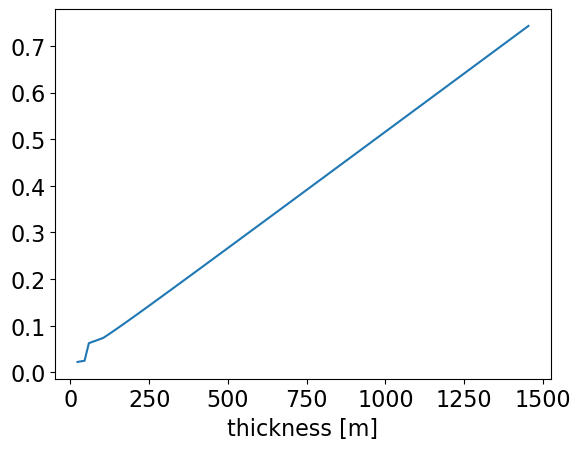

In [21]:
(ds.lwc*(ds.height_bounds_upper-ds.height_bounds_lower)).sum('height').plot()

### Ze & DFR

Text(0.5, 0, '')

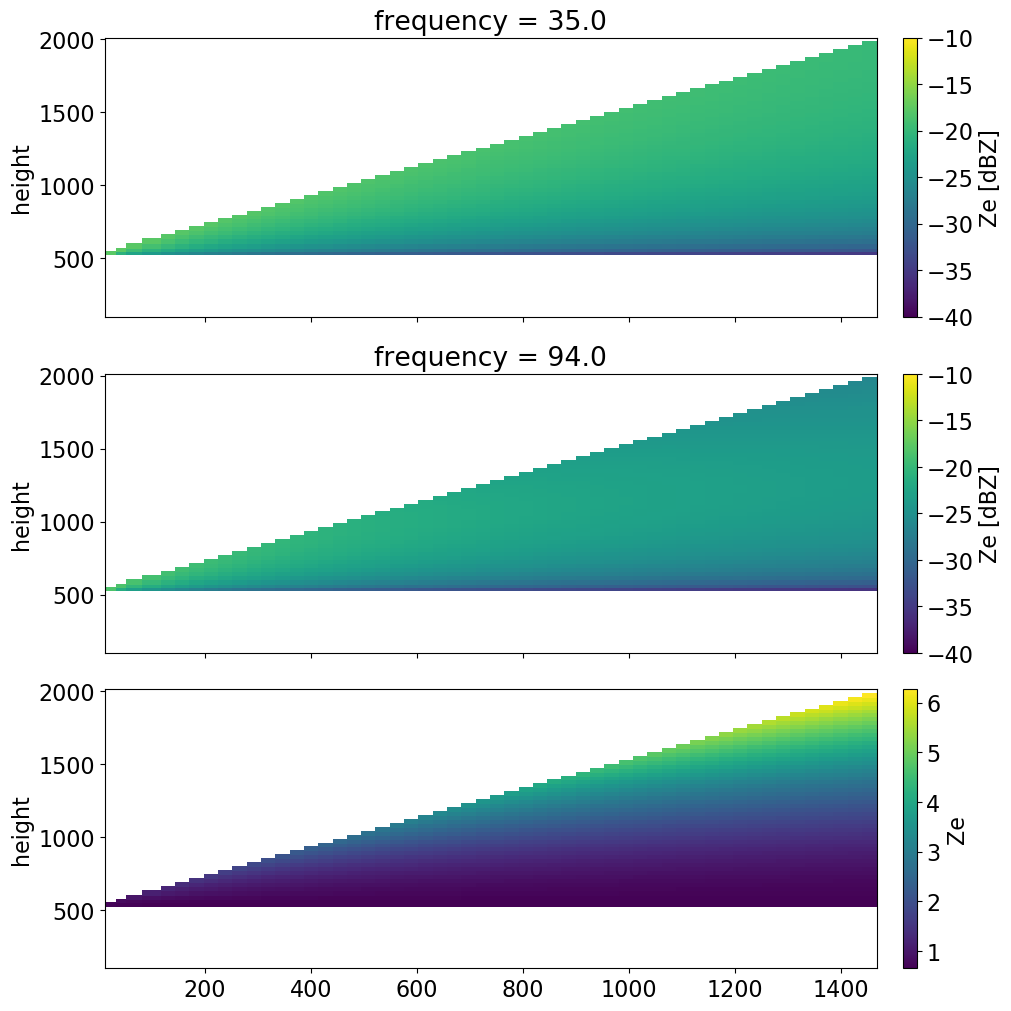

In [22]:
# Ze & DFR
fig, axs = plt.subplots(3,1,sharex=True, sharey=True, constrained_layout=True, figsize=(10,10))
ax = axs[0]
ds.sel(frequency=35.).Ze.T.plot(ax=ax, vmin=-40, vmax=-10)
ax.set_xlabel('')
ax = axs[1]
ds.sel(frequency=94.).Ze.T.plot(ax=ax, vmin=-40, vmax=-10)
ax.set_xlabel('')
ax = axs[2]
(ds.sel(frequency=35.).Ze.T-ds.sel(frequency=94.).Ze.T).plot(ax=ax)
ax.set_xlabel('')

### profiles for 500 m thick cloud

In [23]:
case = ds.sel(thickness=500, method='nearest')

#### Ze profiles

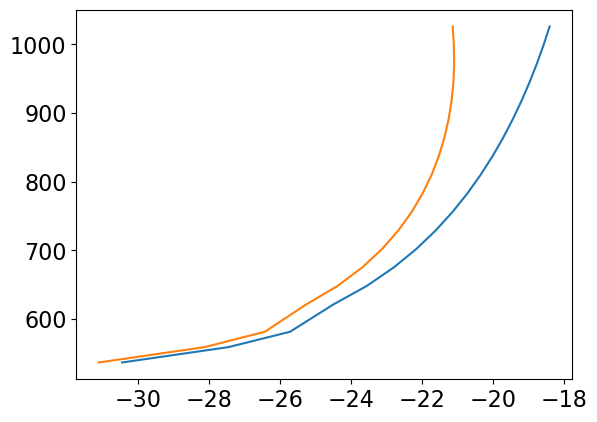

In [24]:
plt.plot(case.sel(frequency=35.).Ze, case.height)
plt.plot(case.sel(frequency=94.).Ze, case.height)

#### DFR profile

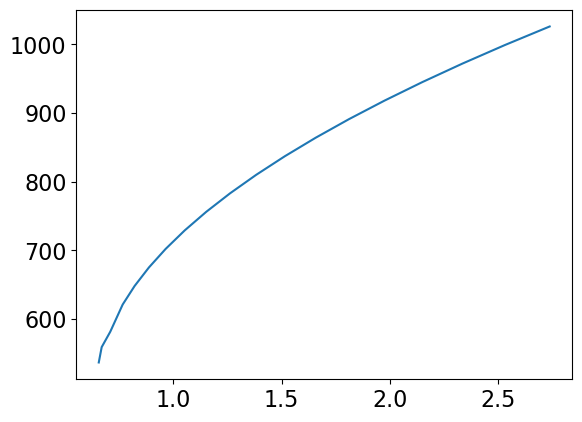

In [25]:
plt.plot(case.sel(frequency=35.).Ze-case.sel(frequency=94.).Ze, case.height)

#### LWC profile

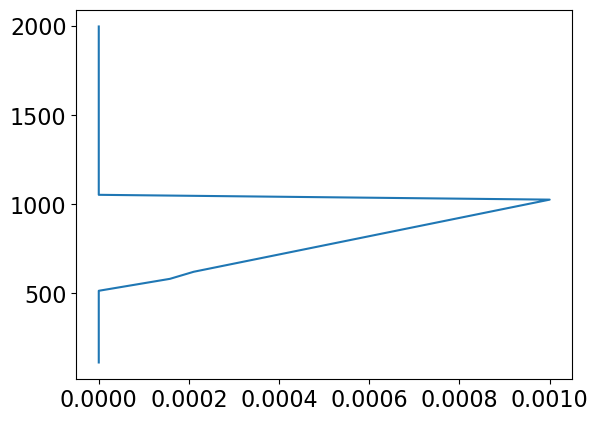

In [26]:
plt.plot(case.lwc, case.height)